# Workshop 2: Scikit-learn and the ML Workflow

## 1. Overview & Setup

### 1.1 Overview
This workshop introduces **Scikit-learn**, the reference Python library for classical machine learning. We will execute the eight steps of an ML workflow on a classification example (Wisconsin Breast Cancer dataset) and a regression example (synthetic server response time).

### 1.2 Setup & Imports
We import the necessary libraries: `numpy`, `pandas`, `matplotlib`, and `sklearn`.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn

print(f"Scikit-learn version: {sklearn.__version__}")


Scikit-learn version: 1.6.1


## 2. Part 1: Scikit-learn

### 2.1 The Estimator Interface
Scikit-learn provides a uniform estimator interface with core methods:
- `model = Algorithm(hyper_parameters)`: Select model family & hyper-parameters.
- `model.fit(X_train, y_train)`: Learn parameters from training data.
- `model.predict(X_new)`: Predict class or value for new data.
- `model.predict_proba(X_new)`: Output class probabilities (classification).
- `model.score(X_test, y_test)`: Compute default performance metric.
- `scaler.fit_transform(X_train)` / `scaler.transform(X_test)`: Preprocessing.

### 2.2 The 8 Steps of the ML Workflow Mapped to Tools
1. **Define the problem**: Identify input features $X$, target $y$, and problem type.
2. **Collect and explore**: `pd.DataFrame`, `describe()`, `value_counts()`, plots.
3. **Prepare**: `train_test_split`, `StandardScaler`, `OneHotEncoder`.
4. **Select a model**: `LogisticRegression()`, `DecisionTreeClassifier()`, etc.
5. **Train**: `model.fit(X_train, y_train)`.
6. **Evaluate**: `confusion_matrix`, `precision_score`, `recall_score`, `r2_score`.
7. **Tune**: `cross_val_score`, `GridSearchCV`, `predict_proba`.
8. **Deploy & Monitor**: `joblib.dump` / `joblib.load`, prediction wrapper function.


## 3. Part 2: The Eight Steps on a Classification Example

### Step 1: Define the Problem
- **Input $X$**: 30 tumour measurements (radius, texture, area, etc.).
- **Output $y$**: Binary classification — Benign (0) vs. Malignant (1, positive class).
- **Goal**: Catch malignant tumours. Missing a malignant tumour (False Negative) is worse than a false alarm (False Positive).


### Step 2: Load and Explore the Data


In [3]:
from sklearn.datasets import load_breast_cancer

data = load_breast_cancer()
X = pd.DataFrame(data.data, columns=data.feature_names)
# Scikit-learn codes benign=1, malignant=0 by default. We recode so malignant=1.
y = pd.Series(1 - data.target, name="malignant")

print("Dataset shape:", X.shape)
print("Class distribution:")
print(y.value_counts())

print("First 5 features descriptive statistics:")
print(X.iloc[:, :5].describe().round(1))

print("Mean feature values by class (first 5 features):")
print(X.groupby(y).mean().iloc[:, :5].round(1))


Dataset shape: (569, 30)
Class distribution:
malignant
0    357
1    212
Name: count, dtype: int64
First 5 features descriptive statistics:
       mean radius  mean texture  mean perimeter  mean area  mean smoothness
count        569.0         569.0           569.0      569.0            569.0
mean          14.1          19.3            92.0      654.9              0.1
std            3.5           4.3            24.3      351.9              0.0
min            7.0           9.7            43.8      143.5              0.1
25%           11.7          16.2            75.2      420.3              0.1
50%           13.4          18.8            86.2      551.1              0.1
75%           15.8          21.8           104.1      782.7              0.1
max           28.1          39.3           188.5     2501.0              0.2
Mean feature values by class (first 5 features):
           mean radius  mean texture  mean perimeter  mean area  \
malignant                                          

### Step 3: Prepare (Split then Scale)

**The Golden Rule**: Always split the dataset into training and test sets *before* applying scaling. Scaling parameters (mean and standard deviation) must be calculated exclusively on the training set to prevent **data leakage**.


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y
)

print(f"X_train shape: {X_train.shape}, X_test shape: {X_test.shape}")

scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

X_train shape: (426, 30), X_test shape: (143, 30)


### Steps 4 & 5: Choose a Model and Train It


In [5]:
from sklearn.linear_model import LogisticRegression

# Step 4: Model Selection
model = LogisticRegression(max_iter=1000)

# Step 5: Training (Gradient descent)
model.fit(X_train_s, y_train)

print("Accuracy on train:", round(model.score(X_train_s, y_train), 3))
print("Accuracy on test: ", round(model.score(X_test_s, y_test), 3))


Accuracy on train: 0.988
Accuracy on test:  0.965


### Step 6: Evaluate with Metrics


Confusion Matrix:
[[89  1]
 [ 4 49]]


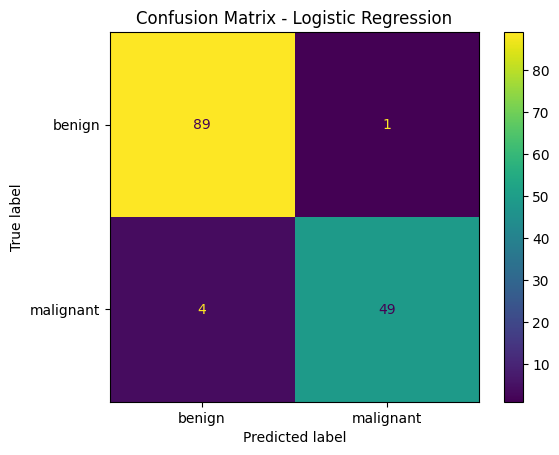

Precision: 0.98
Recall:    0.925
F1 Score:  0.951


In [6]:
from sklearn.metrics import (
    confusion_matrix, ConfusionMatrixDisplay,
    precision_score, recall_score, f1_score
)

y_pred = model.predict(X_test_s)
cm = confusion_matrix(y_test, y_pred)

print("Confusion Matrix:")
print(cm)

disp = ConfusionMatrixDisplay(cm, display_labels=["benign", "malignant"])
disp.plot()
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

print("Precision:", round(precision_score(y_test, y_pred), 3))
print("Recall:   ", round(recall_score(y_test, y_pred), 3))
print("F1 Score: ", round(f1_score(y_test, y_pred), 3))


### Step 7: Tune Threshold and Compare Algorithms

#### 7.1 Moving Decision Threshold


In [7]:
y_prob = model.predict_proba(X_test_s)[:, 1]

for t in [0.3, 0.5, 0.7]:
    yp = (y_prob >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, yp).ravel()
    print(f"Threshold (t={t:.1f}): missed malignant (FN) = {fn:2d}, false alarms (FP) = {fp:2d}")


Threshold (t=0.3): missed malignant (FN) =  2, false alarms (FP) =  1
Threshold (t=0.5): missed malignant (FN) =  4, false alarms (FP) =  1
Threshold (t=0.7): missed malignant (FN) =  5, false alarms (FP) =  0


#### 7.2 Compare Algorithms via Cross-Validation Pipeline


In [8]:
from sklearn.model_selection import cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.tree import DecisionTreeClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier

candidates = {
    "logistic regression": LogisticRegression(max_iter=1000),
    "decision tree": DecisionTreeClassifier(random_state=42),
    "k-nearest neighbours": KNeighborsClassifier(5),
    "random forest": RandomForestClassifier(random_state=42)
}

for name, algo in candidates.items():
    pipe = make_pipeline(StandardScaler(), algo)
    scores = cross_val_score(pipe, X_train, y_train, cv=5)
    print(f"{name:22s} mean accuracy: {scores.mean():.3f}")


logistic regression    mean accuracy: 0.977
decision tree          mean accuracy: 0.908
k-nearest neighbours   mean accuracy: 0.962
random forest          mean accuracy: 0.965


### Step 8: Save, Reload, and Inference


In [9]:
import joblib

final = make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)).fit(X_train, y_train)
print("Final test accuracy:", round(final.score(X_test, y_test), 3))

# Export model file
joblib.dump(final, "tumor_model.joblib")

# Load model file
loaded_model = joblib.load("tumor_model.joblib")

# Run inference on a single observation (1-row DataFrame)
new_case = X_test.iloc[[0]]
pred_class = loaded_model.predict(new_case)
pred_prob = loaded_model.predict_proba(new_case).round(3)
true_label = int(y_test.iloc[0])

print(f"Predicted class: {pred_class[0]}, Probabilities [benign, malignant]: {pred_prob[0]}, True class: {true_label}")


Final test accuracy: 0.965
Predicted class: 1, Probabilities [benign, malignant]: [0.001 0.999], True class: 1


## 4. Part 3: The Same Workflow for Regression

We apply the identical workflow steps to a regression problem predicting server response time based on system load.


In [10]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score

# Step 2: Synthetic log generation
rng = np.random.default_rng(0)
n = 300
users = rng.integers(50, 1200, n)
cpu = np.clip(0.06 * users + rng.normal(0, 8, n), 2, 100).round(1)
resp = (40 + 0.25 * users + 1.5 * cpu + rng.normal(0, 25, n)).round(8)

srv = pd.DataFrame({"users": users, "cpu": cpu, "response_ms": resp})

# Step 1: Define features and target
Xr, yr = srv[["users", "cpu"]], srv["response_ms"]

# Step 3: Train / Test split
Xr_train, Xr_test, yr_train, yr_test = train_test_split(Xr, yr, test_size=0.2, random_state=42)

# Steps 4 & 5: Choose model and fit
reg = LinearRegression().fit(Xr_train, yr_train)

# Step 6: Evaluation metrics
pred = reg.predict(Xr_test)
rmse = np.sqrt(mean_squared_error(yr_test, pred))
r2 = r2_score(yr_test, pred)

print("RMSE:", np.round(rmse, 1), "ms")
print("R2:  ", round(r2, 3))
print(f"Equation: response = {reg.intercept_:.1f} + {reg.coef_[0]:.3f} * users + {reg.coef_[1]:.3f} * cpu")

# Step 8: Deployment inference
sample_pred = reg.predict(pd.DataFrame([[800, 60]], columns=["users", "cpu"])).round(0)
print(f"Prediction: {sample_pred[0]} ms for 800 users at 60 % CPU")


RMSE: 21.3 ms
R2:   0.968
Equation: response = 37.1 + 0.242 * users + 1.668 * cpu
Prediction: 331.0 ms for 800 users at 60 % CPU


## 5. Part 4: Exercises, Checkpoint Questions & Homework

### 5.1 Exercises

#### Exercise 1: Model Comparison with Naive Bayes & SVC
In Cell 2.6, add `GaussianNB()` (from `sklearn.naive_bayes import GaussianNB`) and `SVC()` (from `sklearn.svm import SVC`) to the `candidates` dictionary and evaluate cross-validation accuracy. Populate `ex1_scores` dictionary with mean CV scores.


In [11]:

# Import the new algorithms
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

# Add the new algorithms to candidates
candidates["gaussian naive bayes"] = GaussianNB()
candidates["svc"] = SVC()

print("Updated candidates:")
print(candidates.keys())


Updated candidates:
dict_keys(['logistic regression', 'decision tree', 'k-nearest neighbours', 'random forest', 'gaussian naive bayes', 'svc'])


In [ ]:
# nbgrader test: Exercise 1 verification Skip it !

In [12]:

# Create an empty dictionary
ex1_scores = {}

# Evaluate each algorithm using 5-fold cross-validation
for name, algo in candidates.items():

    pipe = make_pipeline(StandardScaler(), algo)

    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        cv=5
    )

    # Store the mean accuracy
    ex1_scores[name] = scores.mean()

# Display the results
print("Exercise 1 - Cross-validation scores:")

for name, score in ex1_scores.items():
    print(f"{name:22s} mean accuracy: {score:.3f}")


Exercise 1 - Cross-validation scores:
logistic regression    mean accuracy: 0.977
decision tree          mean accuracy: 0.908
k-nearest neighbours   mean accuracy: 0.962
random forest          mean accuracy: 0.965
gaussian naive bayes   mean accuracy: 0.944
svc                    mean accuracy: 0.977


#### Exercise 2: Logistic Regression Without Scaling
Retrain Logistic Regression without scaling (`LogisticRegression(max_iter=1000).fit(X_train, y_train)`). Compute test accuracy as `unscaled_test_acc`.


In [13]:

# Create Logistic Regression model without scaling
unscaled_model = LogisticRegression(max_iter=1000)

# Fit the model using original training data
unscaled_model.fit(X_train, y_train)

# Compute test accuracy without scaling
unscaled_test_acc = unscaled_model.score(X_test, y_test)

# Compute test accuracy with scaling
scaled_test_acc = model.score(X_test_s, y_test)

# Display results
print("Unscaled test accuracy:", round(unscaled_test_acc, 3))
print("Scaled test accuracy:  ", round(scaled_test_acc, 3))


Unscaled test accuracy: 0.951
Scaled test accuracy:   0.965


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [ ]:
# nbgrader test: Exercise 2 verification skip it !

### Exercise 3
A hospital says a missed malignant tumour costs 20 times more than a false alarm. Which threshold of Cell 2.5 would you choose, and why?

In [15]:
# Write your code here

t = 0.3

because = "A missed malignant tumour (FN) costs 20 times more than a false alarm (FP), so I choose a lower threshold to reduce missed malignant cases."

In [ ]:
# Cell to evaluate the threshold ... skip it !

Q1. In which order: split or scale? Why?

In [16]:
answer = "Split first, then scale. We split the dataset into training and testing sets before scaling to prevent data leakage. The scaler must be fitted only on the training data, then used to transform both training and testing data."

Q2. Your model has accuracy 0.99 on a dataset where 1% of the rows are attacks.
Is it a good model?
Which metric do you look at next?

In [17]:
# Write your code here

good_model = False

next_metrics = "Precision, Recall, F1-score, and Confusion Matrix"

 **Q3. What is the difference between `predict` and `predict_proba`?**

In [18]:
response = "predict returns the predicted class label (e.g., 0 or 1), while predict_proba returns the probability of each class (e.g., 20% benign and 80% malignant)."

- **Q4. Give the regression equivalents of `LogisticRegression`, `accuracy` and `confusion_matrix`.**

In [19]:
answer_q4 = "LinearRegression, R-squared (R2) and RMSE/MAE, and regression does not use a confusion_matrix."

### 5.2 Homework: ML Workflow on Login Logs

Apply the eight steps to logins log data:
- Define target: `suspicious = failed_attempts >= 5`.
- Features: `hour`, `duration_min`, `night`, and one-hot encoded `country`.
- Train Logistic Regression and Decision Tree.
- Compute confusion matrix and recall on the test set.


In [20]:

# Homework Setup & Implementation

np.random.seed(42)
n_samples = 500

logins_clean = pd.DataFrame({
    "failed_attempts": np.random.randint(0, 10, size=n_samples),
    "hour": np.random.randint(0, 24, size=n_samples),
    "duration_min": np.random.exponential(scale=15, size=n_samples).round(1),
    "night": np.random.choice([0, 1], size=n_samples),
    "country": np.random.choice(["US", "FR", "CN", "RU", "DE"], size=n_samples)
})

# 1. Target definition
logins_clean["suspicious"] = (
    logins_clean["failed_attempts"] >= 5
).astype(int)

# 2. Features and One-Hot Encoding
X_hw = logins_clean[["hour", "duration_min", "night", "country"]]

X_hw = pd.get_dummies(X_hw, columns=["country"], dtype=int)

y_hw = logins_clean["suspicious"]

# 3. Split then scale
X_hw_train, X_hw_test, y_hw_train, y_hw_test = train_test_split(
    X_hw, y_hw,
    test_size=0.25,
    random_state=42,
    stratify=y_hw
)

scaler_hw = StandardScaler()

X_hw_train_s = scaler_hw.fit_transform(X_hw_train)
X_hw_test_s = scaler_hw.transform(X_hw_test)

# 4 & 5. Train models
log_reg_hw = LogisticRegression(max_iter=1000)
log_reg_hw.fit(X_hw_train_s, y_hw_train)

tree_hw = DecisionTreeClassifier(random_state=42)
tree_hw.fit(X_hw_train, y_hw_train)

# 6. Evaluate
y_pred_log_hw = log_reg_hw.predict(X_hw_test_s)
y_pred_tree_hw = tree_hw.predict(X_hw_test)

cm_log_hw = confusion_matrix(y_hw_test, y_pred_log_hw)
cm_tree_hw = confusion_matrix(y_hw_test, y_pred_tree_hw)

recall_log_hw = recall_score(y_hw_test, y_pred_log_hw)
recall_tree_hw = recall_score(y_hw_test, y_pred_tree_hw)

print("Logistic Regression - Recall:", round(recall_log_hw, 3))
print("Decision Tree - Recall:      ", round(recall_tree_hw, 3))


Logistic Regression - Recall: 0.148
Decision Tree - Recall:       0.41


In [ ]:
# nbgrader test: Homework verification skip it !

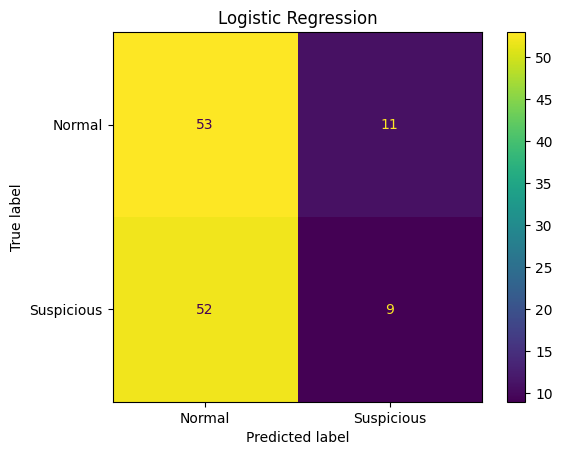

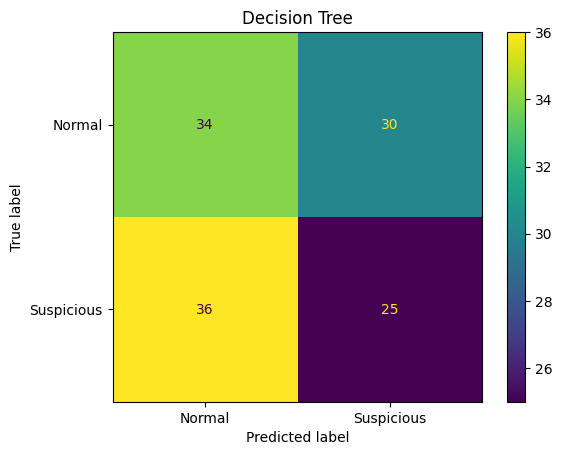

In [21]:
# Logistic Regression Confusion Matrix
disp1 = ConfusionMatrixDisplay(
    confusion_matrix=cm_log_hw,
    display_labels=["Normal", "Suspicious"]
)
disp1.plot()
plt.title("Logistic Regression")
plt.show()

# Decision Tree Confusion Matrix
disp2 = ConfusionMatrixDisplay(
    confusion_matrix=cm_tree_hw,
    display_labels=["Normal", "Suspicious"]
)
disp2.plot()
plt.title("Decision Tree")
plt.show()

In [22]:
# Compare model recall
if recall_log_hw > recall_tree_hw:
    print("Logistic Regression has better Recall.")
elif recall_tree_hw > recall_log_hw:
    print("Decision Tree has better Recall.")
else:
    print("Both models have the same Recall.")

Decision Tree has better Recall.


**Homework Limitations Discussion:**
Expect a weak model because the underlying data is generated randomly without true statistical dependency between inputs and the target. This highlights that machine learning models cannot extract non-existent signal from uninformative noise, confirming that strictly following the 8-step ML procedure allows us to reliably assess model viability.
